# 10 — Validação da hipótese: "quanto mais demorada a corrida, mais lucramos"

**Atenção ao alvo:** a base tem `vlr_pago`, que é a **receita bruta** por corrida. Não há custo (combustível, repasse ao motorista, taxas), portanto **lucro não pode ser medido**. A hipótese é testada como *“corridas mais demoradas geram mais receita”*, e a conclusão sobre lucro fica condicionada a dados de custo.

**Testes:**
1. Correlação de Pearson e Spearman entre `duracao` e `vlr_pago`.
2. Regressão linear simples `vlr_pago ~ duracao`.
3. Regressão múltipla `vlr_pago ~ duracao + distancia_lalo`, para saber se a duração tem efeito **além** da distância, já que as duas crescem juntas.
4. Receita por minuto em faixas de duração, que mostra a eficiência do tempo do motorista.

Nível de significância: **α = 0,05**.

In [1]:
%pip install "statsmodels>=0.14.5" --quiet

In [2]:
%restart_python

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

ALFA = 0.05
df = spark.table("desloc.gold.transacoes_eda").toPandas()[["duracao", "vlr_pago", "distancia_lalo", "periodo"]].astype(float)
print(f"Corridas: {len(df)}")

Corridas: 104


## 1. Correlação

Calculada com e sem a corrida outlier de 106 min (ver notebook 09). O Spearman usa postos, então é robusto ao outlier e a relações não lineares.

In [4]:
sem_outlier = df[df.duracao <= 50]
linhas = []
for rotulo, dados in [("todas", df), ("sem outlier (>50 min)", sem_outlier)]:
    p = stats.pearsonr(dados.duracao, dados.vlr_pago)
    s = stats.spearmanr(dados.duracao, dados.vlr_pago)
    linhas.append({"base": rotulo, "n": len(dados), "pearson_r": p.statistic, "pearson_p": p.pvalue,
                   "spearman_rho": s.statistic, "spearman_p": s.pvalue})
correlacoes = pd.DataFrame(linhas)
display(correlacoes.round(4))

base,n,pearson_r,pearson_p,spearman_rho,spearman_p
todas,104,0.3268,0.0007,0.6741,0
sem outlier (>50 min),103,0.4997,0,0.6661,0


## 2. Regressões

In [5]:
simples = smf.ols("vlr_pago ~ duracao", data=sem_outlier).fit()
multipla = smf.ols("vlr_pago ~ duracao + distancia_lalo", data=sem_outlier).fit()
resumo = pd.DataFrame([
    {"modelo": "vlr_pago ~ duracao", "coef_duracao_R$_por_min": simples.params.duracao,
     "p_valor": simples.pvalues.duracao, "IC95_inf": simples.conf_int().loc["duracao", 0],
     "IC95_sup": simples.conf_int().loc["duracao", 1], "R2": simples.rsquared},
    {"modelo": "vlr_pago ~ duracao + distancia_lalo", "coef_duracao_R$_por_min": multipla.params.duracao,
     "p_valor": multipla.pvalues.duracao, "IC95_inf": multipla.conf_int().loc["duracao", 0],
     "IC95_sup": multipla.conf_int().loc["duracao", 1], "R2": multipla.rsquared},
])
display(resumo.round(4))
print(multipla.summary().tables[1])

modelo,coef_duracao_R$_por_min,p_valor,IC95_inf,IC95_sup,R2
vlr_pago ~ duracao,0.3714,0,0.2443,0.4985,0.2497
vlr_pago ~ duracao + distancia_lalo,0.0725,0.0004,0.0329,0.112,0.9416


                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          8.1135      0.374     21.677      0.000       7.371       8.856
duracao            0.0725      0.020      3.635      0.000       0.033       0.112
distancia_lalo     3.6059      0.105     34.435      0.000       3.398       3.814


## 3. Receita por minuto em faixas de duração

In [6]:
sem_outlier = sem_outlier.assign(receita_por_min=sem_outlier.vlr_pago / sem_outlier.duracao,
                                 faixa_duracao=pd.qcut(sem_outlier.duracao, 4))
faixas = sem_outlier.groupby("faixa_duracao", observed=True).agg(
    corridas=("vlr_pago", "size"), receita_media=("vlr_pago", "mean"),
    receita_por_min=("receita_por_min", "mean"), distancia_media_km=("distancia_lalo", "mean"))
display(faixas.round(2))

corridas,receita_media,receita_por_min,distancia_media_km
26,19.4,2.75,3
43,23.02,2.28,3.95
8,24.75,2.06,4.29
26,25.15,1.54,4.35


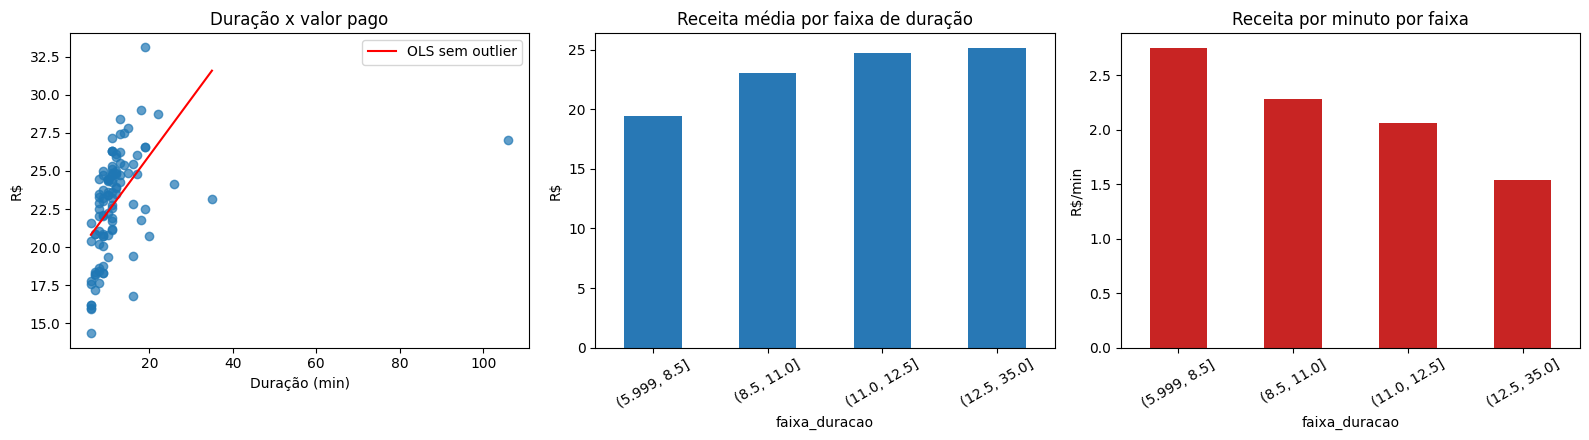

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(df.duracao, df.vlr_pago, alpha=.7)
x = np.linspace(sem_outlier.duracao.min(), sem_outlier.duracao.max(), 50)
ax[0].plot(x, simples.params.Intercept + simples.params.duracao * x, "r-", label="OLS sem outlier")
ax[0].set(title="Duração x valor pago", xlabel="Duração (min)", ylabel="R$"); ax[0].legend()
faixas["receita_media"].plot.bar(ax=ax[1], color="#2878B5", title="Receita média por faixa de duração", ylabel="R$")
faixas["receita_por_min"].plot.bar(ax=ax[2], color="#C82423", title="Receita por minuto por faixa", ylabel="R$/min")
for a in ax[1:]: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 4. Decisão

In [8]:
r = correlacoes.iloc[1]
efeito_ajustado = resumo.iloc[1]
receita_confirmada = (r.pearson_p < ALFA) and (r.pearson_r > 0) and (efeito_ajustado.p_valor < ALFA) \
    and (efeito_ajustado["coef_duracao_R$_por_min"] > 0)
eficiencia_cai = faixas.receita_por_min.iloc[-1] < faixas.receita_por_min.iloc[0]

print(f"H0: não há relação positiva entre duração e receita (α = {ALFA})")
print(f"- Pearson r = {r.pearson_r:.3f} (p = {r.pearson_p:.2e}); Spearman ρ = {r.spearman_rho:.3f}")
print(f"- Controlando a distância: +R$ {efeito_ajustado['coef_duracao_R$_por_min']:.3f} por minuto "
      f"(p = {efeito_ajustado.p_valor:.2e})")
print("RESULTADO (receita):", "H0 rejeitada — corridas mais demoradas geram MAIS receita" if receita_confirmada
      else "H0 não rejeitada")
print("EFICIÊNCIA:", "a receita por minuto CAI nas corridas mais longas" if eficiencia_cai
      else "a receita por minuto não cai nas corridas longas")
print("LUCRO: não validável — a base não tem custos; vlr_pago é receita bruta.")

spark.createDataFrame(pd.DataFrame([{
    "pearson_r": float(r.pearson_r), "pearson_p": float(r.pearson_p), "spearman_rho": float(r.spearman_rho),
    "coef_duracao_ajustado": float(efeito_ajustado["coef_duracao_R$_por_min"]),
    "p_duracao_ajustado": float(efeito_ajustado.p_valor), "r2_multipla": float(efeito_ajustado.R2),
    "receita_confirmada": bool(receita_confirmada), "receita_por_min_cai": bool(eficiencia_cai)}])) \
    .write.mode("overwrite").option("overwriteSchema", "true").saveAsTable("desloc.gold.validacao_hipotese")

H0: não há relação positiva entre duração e receita (α = 0.05)
- Pearson r = 0.500 (p = 7.74e-08); Spearman ρ = 0.666
- Controlando a distância: +R$ 0.072 por minuto (p = 4.42e-04)
RESULTADO (receita): H0 rejeitada — corridas mais demoradas geram MAIS receita
EFICIÊNCIA: a receita por minuto CAI nas corridas mais longas
LUCRO: não validável — a base não tem custos; vlr_pago é receita bruta.


## 5. Conclusão para o negócio

- **Receita:** a hipótese é **sustentada**. A duração tem correlação positiva e significativa com o valor pago, e o efeito continua positivo mesmo controlando a distância, ou seja, o tempo de corrida é cobrado além dos quilômetros.
- **Eficiência:** cada minuto adicional rende **menos** que os primeiros minutos. Corridas longas aumentam a receita total por corrida, mas reduzem a receita por minuto do motorista.
- **Lucro:** **não validado**. Sem custos por corrida, não dá para afirmar que corridas longas são mais lucrativas. Próximo passo: coletar custos (km rodado, repasse, combustível) e repetir o teste com margem.
- **Impacto no modelo:** por isso a duração estimada (notebook 09) entra como feature do preço (notebook 11).